# 03 - Analysis

In [1]:
import pandas as pd

students = pd.read_csv("../data/processed/students_clean.csv")
scores = pd.read_csv("../data/processed/scores_clean.csv")
activity = pd.read_csv("../data/processed/activity_clean.csv")

In [4]:
counts = students["final_result"].value_counts()
percents = (students["final_result"].value_counts(normalize=True) * 100).round(1)
df = pd.DataFrame({"count": counts, "percent": percents})
print(df)

              count  percent
final_result                
Pass            120     40.0
Fail             71     23.7
Withdrawn        64     21.3
Distinction      45     15.0


In [6]:
activity_summary = activity.groupby("student_id").agg(
    weeks_active=("week", "count"),
    total_checks=("clicks", "sum"),
    avg_weekly_clicks=("clicks", "mean")
).reset_index()

activity_summary.head()

,student_id,weeks_active,total_checks,avg_weekly_clicks
0,1001,3,90,30.0
1,1002,10,366,36.6
2,1003,10,447,44.7
3,1004,10,385,38.5
4,1005,10,404,40.4


In [7]:
data = students.merge(activity_summary, on="student_id", how="left")
print(data.head())

   student_id gender age_band     region highest_education final_result  \
0        1001      M     0-35    Chennai          Graduate    Withdrawn   
1        1002      M     0-35  Bengaluru          Graduate         Pass   
2        1003      M     0-35      Delhi      Postgraduate         Pass   
3        1004      F     0-35     Mumbai      Postgraduate         Fail   
4        1005      F     0-35      Delhi      Postgraduate         Fail   

   weeks_active  total_checks  avg_weekly_clicks  
0             3            90               30.0  
1            10           366               36.6  
2            10           447               44.7  
3            10           385               38.5  
4            10           404               40.4  


In [13]:
data.groupby("final_result")[["weeks_active", "total_checks", "avg_weekly_clicks"]].mean().round(1)

,weeks_active,total_checks,avg_weekly_clicks
final_result,,,
Distinction,10.0,455.5,45.5
Fail,10.0,253.6,25.4
Pass,10.0,387.7,38.8
Withdrawn,4.7,110.2,23.7


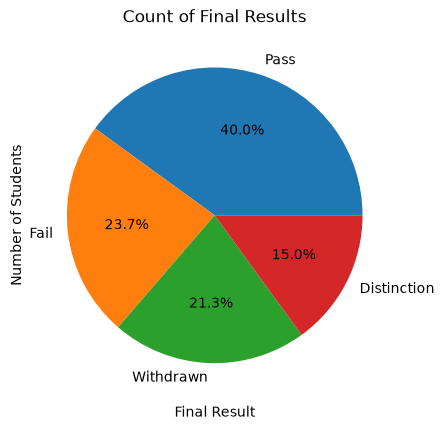

In [22]:
import matplotlib.pyplot as plt

data["final_result"].value_counts().plot(
    kind="pie", 
    color=["green", "red", "blue", "black"],
    autopct="%1.1f%%",
)
plt.title("Count of Final Results")
plt.xlabel("Final Result")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()
